# A Particle in a Rigid Box, Interpreted; Picking a Quantum Model; and Keeping the Experiment Still

**Colin Casey, 2026.** Knight, *Physics for Scientists and Engineers*, 5e, **§40.4** "A Particle in a Rigid Box: Interpreting the Solution" (with 40.5, 40.8). Library: `dgs/box_model_isolation.py` (tests: `tests/test_box_model_isolation.py`). Also exported as a web page: `notebooks/box_model_isolation.html`.

## In plain words

1. **Interpreting the box.** $\psi_n=\sqrt{2/L}\sin(n\pi x/L)$ says *where the particle is likely to be*. It has $n-1$ **nodes**, places it is never found. Exact integrals give the probability in any region. As $n$ grows, everything approaches the classical answer: a ball bouncing between walls is equally likely to be anywhere (the correspondence principle). **Lean + Mathlib** proves the limit.
2. **Picking a quantum model** for atomic, molecular and optical (AMO) remote sensing and quantum information (QIS). A model is right *for a question*:
   * **QIS:** can a laser drive each transition separately? Box levels: yes. Their gaps are all different, so **64 levels form a 64-level qudit, the same as 6 qubits**. Harmonic levels: no, every gap is the same. That's why qubits need anharmonicity.
   * **Remote sensing:** where is the CO absorption line? The harmonic model misses the overtone by thousands of Doppler widths, so the laser would see nothing. The anharmonic model hits it.
   * **Atom traps:** score each model by the *shape* of its spectrum. A Gaussian tweezer picks harmonic; a steep-walled trap picks the box.
3. **Vibration isolation (analytical mechanics).** All of the above sits on a table that the floor shakes. Lagrange's equations with a dissipation function give the transmissibility. One stage isolates only above $\sqrt2\,f_0$ and falls as $1/f^2$; two stages fall as $1/f^4$.

| your words | section |
|---|---|
| 40.4 interpreting the solution | §1–§2 |
| 64 bit | §3 (64 levels = 6 qubits; and why 64 *qubits* won't fit in memory) |
| remote sensing in AMO | §4 |
| picking a quantum mechanical model | §3–§5 |
| analytical mechanics for vibration isolation | §6 |
| sympy, lean, jupyter, web | throughout; Lean in §2; HTML export at the end |

Kernel: **py312**.

In [1]:
import shutil, subprocess, pathlib, time
import numpy as np
import sympy as sp
sp.init_printing()
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Math
from dgs import box_model_isolation as b
OI = dict(orange='#E69F00', sky='#56B4E9', green='#009E73', yellow='#F0E442', blue='#0072B2', red='#D55E00', purple='#CC79A7', black='#000000')
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})

## 1. Interpreting the rigid-box solution (Knight 40.4)

The probability of finding the particle between $a$ and $b$ is $\int_a^b|\psi_n|^2dx$. SymPy does it exactly, and then takes $n\to\infty$:

In [2]:
P = b.box_probability_sym()
display(Math(r'P_n(a<x<b) = ' + sp.latex(P)))
display(Math(r'\lim_{n\to\infty} P_n = ' + sp.latex(sp.limit(P, b.n_s, sp.oo)) + r'\quad\text{(classical: uniform)}'))
mx, mx2, dx = b.box_moments_sym()
display(Math(r'\langle x\rangle = ' + sp.latex(mx) + r',\quad \Delta x = ' + sp.latex(dx) + r'\;\xrightarrow{n\to\infty}\; \frac{L}{\sqrt{12}}'))
rows = [dict(n=n, P_left_quarter=b.box_probability(n, 0, 0.25), nodes=', '.join(f'{v:.3g}' for v in b.box_nodes(n)) or '-',
             delta_x_over_L=b.box_delta_x(n), relative_spacing=float(b.relative_spacing(n))) for n in (1, 2, 3, 4, 10, 64)]
pd.DataFrame(rows)

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

,n,P_left_quarter,nodes,delta_x_over_L,relative_spacing
0,1,0.090845,-,0.180756,3.000000
1,2,0.250000,0.5,0.265835,1.250000
2,3,0.303052,"0.333, 0.667",0.278755,0.777778
3,4,0.250000,"0.25, 0.5, 0.75",0.283138,0.562500
4,10,0.250000,"0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9",0.287796,0.210000
5,64,0.250000,"0.0156, 0.0312, 0.0469, 0.0625, 0.0781, 0.0938...",0.288654,0.031494


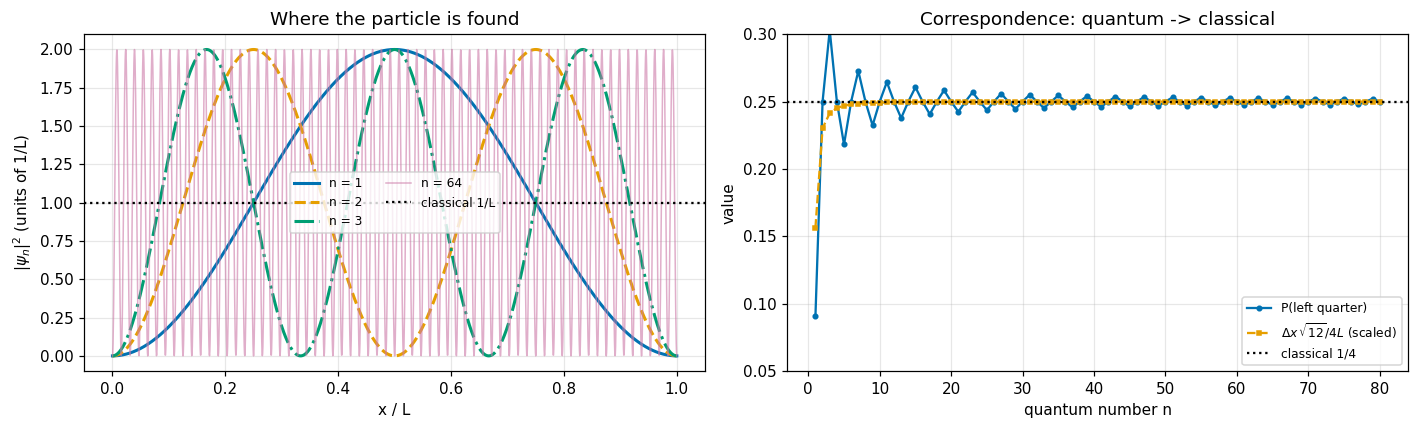

Figure 1. Left: probability density for n = 1 (solid blue), 2 (dashed orange), 3 (dash-dot green) and 64 (thin purple), against the classical uniform 1/L (dotted). n = 1 peaks in the middle; n = 2 has a node at L/2 where the particle is never found; n = 64 oscillates so fast that it averages to the classical line. Right: the probability of the left quarter (blue circles) and the scaled spread Delta x (orange squares) both settle onto the classical 1/4 (dotted) as n grows. Even n land exactly on 1/4 (sin(n pi / 2) = 0); odd n alternate below and above it (n = 1: 0.091, n = 3: 0.303), with the miss shrinking like 1/(2 n pi).


In [3]:
x = np.linspace(0, 1, 2001)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for n, c_, ls in [(1, OI['blue'], '-'), (2, OI['orange'], '--'), (3, OI['green'], '-.'), (64, OI['purple'], '-')]:
    ax[0].plot(x, 2*np.sin(n*np.pi*x)**2, ls, color=c_, lw=1 if n == 64 else 2, alpha=0.6 if n == 64 else 1, label=f'n = {n}')
ax[0].axhline(1, color=OI['black'], ls=':', label='classical 1/L')
ax[0].set(xlabel='x / L', ylabel='$|\\psi_n|^2$ (units of 1/L)', title='Where the particle is found'); ax[0].legend(fontsize=8, ncol=2)
ns = np.arange(1, 81)
ax[1].plot(ns, [b.box_probability(n, 0, 0.25) for n in ns], 'o-', ms=3, color=OI['blue'], label='P(left quarter)')
ax[1].plot(ns, b.box_delta_x(ns)*np.sqrt(12)*0.25, 's--', ms=3, color=OI['orange'], label='$\\Delta x\\,\\sqrt{12}/4L$ (scaled)')
ax[1].axhline(0.25, color=OI['black'], ls=':', label='classical 1/4')
ax[1].set(xlabel='quantum number n', ylabel='value', ylim=(0.05, 0.3), title='Correspondence: quantum -> classical'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 1. Left: probability density for n = 1 (solid blue), 2 (dashed orange), 3 (dash-dot green) and 64 (thin purple), '
      'against the classical uniform 1/L (dotted). n = 1 peaks in the middle; n = 2 has a node at L/2 where the particle is '
      'never found; n = 64 oscillates so fast that it averages to the classical line. Right: the probability of the left '
      'quarter (blue circles) and the scaled spread Delta x (orange squares) both settle onto the classical 1/4 (dotted) as n '
      'grows. Even n land exactly on 1/4 (sin(n pi / 2) = 0); odd n alternate below and above it (n = 1: 0.091, n = 3: '
      '0.303), with the miss shrinking like 1/(2 n pi).')

## 2. Lean 4 + Mathlib: the interpretation, proved

Compiled against Mathlib in `~/lean/NavierStokesAndEuler` with narrow imports:
* `box_gap`, `box_gaps_distinct`: box gaps $(2n+1)E_1$ are all different (used in §3).
* `correspondence_spacing`: $\lim_{n\to\infty}(2n+1)/n^2=0$, a genuine `Tendsto`. This is the correspondence principle for level spacing.
* `harmonic_gap`: every harmonic gap is the same $\hbar\omega$.
* `isolation_above_sqrt2`: an undamped isolator transmits less than it receives only when $r^2>2$ (used in §6).

The cell reports the real compiler result. If Lean or Mathlib is missing, it says the proofs were **not** verified.

In [4]:
LEAN_SRC = r'''
import Mathlib.Analysis.SpecificLimits.Basic
import Mathlib.Tactic.FieldSimp
import Mathlib.Tactic.Ring
import Mathlib.Tactic.Positivity
import Mathlib.Tactic.Linarith

open Filter Topology

/-- Box levels E_n = n^2 E_1: neighbouring levels differ by (2n+1) E_1 (every gap is different). -/
theorem box_gap (E1 : ℝ) (n : ℕ) : ((n:ℝ) + 1) ^ 2 * E1 - (n:ℝ) ^ 2 * E1 = (2 * n + 1) * E1 := by
  ring

/-- Box transitions n -> n+1 have distinct frequencies: (2n+1) = (2m+1) forces n = m (addressable qudit). -/
theorem box_gaps_distinct (n m : ℕ) (h : 2 * n + 1 = 2 * m + 1) : n = m := by
  omega

/-- Correspondence principle: relative level spacing (2n+1)/n^2 -> 0 as n -> infinity. -/
theorem correspondence_spacing :
    Tendsto (fun n : ℕ => (2 * (n:ℝ) + 1) / (n:ℝ) ^ 2) atTop (𝓝 0) := by
  have h1 : Tendsto (fun n : ℕ => (1:ℝ) / (n:ℝ)) atTop (𝓝 0) := tendsto_one_div_atTop_nhds_zero_nat
  have h2 : Tendsto (fun n : ℕ => 2 * ((1:ℝ) / n) + ((1:ℝ) / n) * ((1:ℝ) / n)) atTop (𝓝 (2 * 0 + 0 * 0)) :=
    (h1.const_mul 2).add (h1.mul h1)
  simp only [mul_zero, add_zero] at h2
  refine h2.congr' ?_
  filter_upwards [eventually_ne_atTop 0] with n hn
  have : (n:ℝ) ≠ 0 := by exact_mod_cast hn
  field_simp

/-- Undamped isolator: transmissibility |1/(1 - r^2)| < 1 exactly when r^2 > 2 (drive above sqrt 2 x resonance). -/
theorem isolation_above_sqrt2 (r2 : ℝ) (h : 2 < r2) : |1 / (1 - r2)| < 1 := by
  have hneg : 1 - r2 < 0 := by linarith
  rw [abs_div, abs_one, abs_of_neg hneg, div_lt_one (by linarith)]
  linarith

/-- Harmonic levels are equally spaced: every n -> n+1 gap is the same hbar*omega (not addressable). -/
theorem harmonic_gap (hw : ℝ) (n : ℕ) : ((n:ℝ) + 1 + 1/2) * hw - ((n:ℝ) + 1/2) * hw = hw := by
  ring
'''

proj = pathlib.Path.home() / 'lean' / 'NavierStokesAndEuler'
lake = shutil.which('lake') or str(pathlib.Path.home() / '.elan' / 'bin' / 'lake.exe')
lean_file = pathlib.Path.cwd() / 'box_model_isolation.lean'
lean_file.write_text(LEAN_SRC.strip() + '\n', encoding='utf-8')
names = [l.split()[1] for l in LEAN_SRC.splitlines() if l.startswith('theorem ')]
if proj.exists() and pathlib.Path(lake).exists():
    t0 = time.perf_counter()
    r = subprocess.run([lake, 'env', 'lean', str(lean_file)], cwd=proj, capture_output=True, text=True, timeout=1200)
    log = (r.stdout + r.stderr).strip()
    lean_ok = r.returncode == 0 and 'sorry' not in log
    print(f'{lean_file.name}: exit code {r.returncode} in {time.perf_counter()-t0:.1f} s; theorems: {", ".join(names)}')
    print(log or 'no errors or warnings: every theorem was checked by the Lean kernel against Mathlib')
else:
    lean_ok = False
    print('Mathlib project or lake not found: written but NOT compiled, nothing verified')

box_model_isolation.lean: exit code 0 in 12.5 s; theorems: box_gap, box_gaps_distinct, correspondence_spacing, isolation_above_sqrt2, harmonic_gap
no errors or warnings: every theorem was checked by the Lean kernel against Mathlib


## 3. Picking a model for QIS: 64 levels as a qudit (and why not 64 qubits)

A laser drives the transition $n\to n+1$ at frequency $(E_{n+1}-E_n)/h$. If two transitions share a frequency, the laser can't drive one without the other. Box gaps $(2n+1)E_1$ are all distinct (Lean, §2), so the lowest **64 box levels** can be addressed one by one: a 64-level **qudit**, as much state space as **6 qubits** ($2^6=64$). Harmonic gaps are all equal, so the oscillator's levels can't be separated by frequency. That's why transmons and ions rely on *anharmonicity*.

"64-bit" the other way: a register of **64 qubits** has $2^{64}$ amplitudes. Storing them as complex128 needs $2^{64}\times16$ bytes, which is why such states aren't simulated by brute force.

box: 63 transition frequencies, smallest separation between any two = 2 E1/h
harmonic: 63 transitions, smallest separation = 0 (all identical: not addressable)
64 levels = 2^6 -> 6 qubits of state space. 64 qubits -> 2^64 amplitudes = 295 exabytes as complex128.


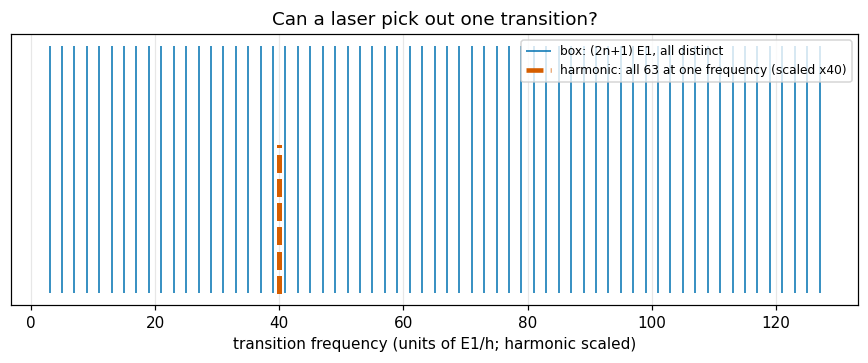

Figure 2. Transition frequencies of the lowest 64 levels. Blue lines (solid): the box gaps 3, 5, 7, ... 127 E1/h, every one at its own frequency. Red (dashed, one thick line): all 63 harmonic transitions fall at the same frequency hbar omega (placed at 40 units for visibility). Only the box levels can be addressed one at a time.


In [5]:
gb, gh = b.transition_gaps('box', 64), b.transition_gaps('harmonic', 64)
print(f'box: 63 transition frequencies, smallest separation between any two = {b.min_gap_separation(gb):.0f} E1/h')
print(f'harmonic: 63 transitions, smallest separation = {b.min_gap_separation(gh):.0f} (all identical: not addressable)')
print(f'64 levels = 2^{int(np.log2(64))} -> 6 qubits of state space. 64 qubits -> 2^64 amplitudes = '
      f'{2.0**64*16/1e18:.0f} exabytes as complex128.')
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.vlines(gb, 0, 1, color=OI['blue'], lw=1, label='box: (2n+1) E1, all distinct')
ax.vlines(gh*40, 0, 0.6, color=OI['red'], lw=3, linestyles='--', label='harmonic: all 63 at one frequency (scaled x40)')
ax.set(xlabel='transition frequency (units of E1/h; harmonic scaled)', yticks=[], title='Can a laser pick out one transition?'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 2. Transition frequencies of the lowest 64 levels. Blue lines (solid): the box gaps 3, 5, 7, ... 127 E1/h, every '
      'one at its own frequency. Red (dashed, one thick line): all 63 harmonic transitions fall at the same frequency '
      'hbar omega (placed at 40 units for visibility). Only the box levels can be addressed one at a time.')

## 4. Picking a model for AMO remote sensing: where is the CO line?

Laser remote sensing of carbon monoxide (open-path or lidar absorption) tunes a narrow laser onto one rovibrational band. The line sits inside a Doppler profile only ~0.005 cm⁻¹ wide. The vibrational ladder of a diatomic molecule is predicted by
* **harmonic:** $\tilde\nu_{0\to v}=v\,\omega_e$;
* **anharmonic (Morse):** $\tilde\nu_{0\to v}=v\,\omega_e-v(v+1)\,\omega_ex_e$.

CO constants are $\omega_e=2169.81$, $\omega_ex_e=13.29$ cm⁻¹ (from memory; check against Huber & Herzberg or HITRAN).

In [6]:
hv, an = b.vib_band_origins(b.CO['we'], b.CO['wexe'])
rows = []
for v in (1, 2, 3):
    dop = b.doppler_hwhm_cm(an[v-1], b.CO['mass_amu'])
    rows.append(dict(band=f'0 -> {v}', harmonic_cm=hv[v-1], anharmonic_cm=an[v-1], anharmonic_um=1e4/an[v-1],
                     harmonic_miss_cm=hv[v-1]-an[v-1], doppler_HWHM_cm=dop, miss_in_doppler_widths=(hv[v-1]-an[v-1])/dop))
display(pd.DataFrame(rows).round(4))
print('Known band origins: fundamental ~2143.3 cm^-1 (4.67 um), first overtone ~4260 cm^-1 (2.35 um). The anharmonic model lands on '
      'them; the harmonic model would tune the laser ~80 cm^-1 (~16,000 Doppler widths) away from the overtone, onto nothing.')

,band,harmonic_cm,anharmonic_cm,anharmonic_um,harmonic_miss_cm,doppler_HWHM_cm,miss_in_doppler_widths
0,0 -> 1,2169.8136,2143.2370,4.6658,26.5766,0.0025,10648.7601
1,0 -> 2,4339.6272,4259.8973,2.3475,79.7299,0.0050,16072.7933
2,0 -> 3,6509.4407,6349.9810,1.5748,159.4597,0.0074,21564.9302


Known band origins: fundamental ~2143.3 cm^-1 (4.67 um), first overtone ~4260 cm^-1 (2.35 um). The anharmonic model lands on them; the harmonic model would tune the laser ~80 cm^-1 (~16,000 Doppler widths) away from the overtone, onto nothing.


## 5. Picking a model for an atom trap: let the spectrum's shape decide (Fig. 3)

A ⁸⁷Rb atom in a trap $V=U_0\,[1-e^{-2|x/w|^p}]$ with $U_0/k_B=100$ µK and $w=1$ µm. $p=2$ is a Gaussian optical tweezer; large $p$ is a flat-top trap with steep walls. Finite differences give the exact levels. Each model is scored by the **shape** of its spectrum, the ratios $E_n/E_1$, which no choice of size or depth can fake. Then the one size parameter is fitted.

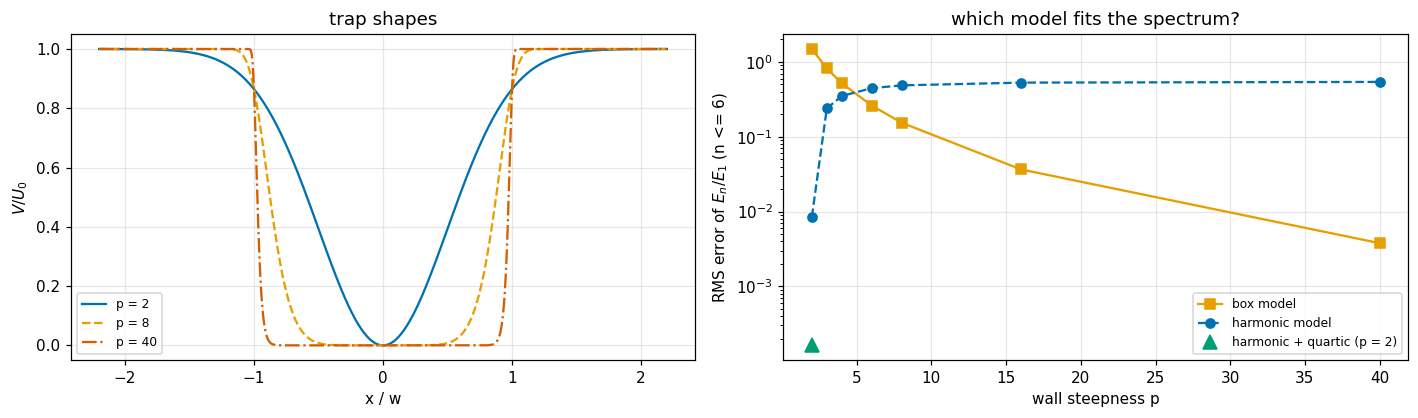

Figure 3. Left: trap potentials for p = 2 (Gaussian tweezer, solid blue), 8 (dashed orange) and 40 (nearly a box, dash-dot red). Right: shape error of each model against the exact finite-difference spectrum (log scale): the harmonic model (blue circles) wins for the Gaussian, and its first-order quartic correction (green triangle) is better still; the box (orange squares) wins once the walls are steep (p >= 8) and becomes nearly exact by p = 40. Around p = 4 neither fits: the honest answer there is a third model (a quartic oscillator), not the closer of two wrong ones.


,order_p,best_model,box_shape_err,harmonic_shape_err,harm_plus_quartic_err,fitted_box_L_um
0,2,harmonic_plus_quartic,1.4893,0.0085,0.0002,0.1923
1,3,harmonic,0.8171,0.2392,NaN,0.3322
2,4,harmonic,0.5191,0.3499,NaN,0.4735
3,6,box,0.2613,0.4460,NaN,0.7260
4,8,box,0.1542,0.4858,NaN,0.9278
5,16,box,0.0366,0.5289,NaN,1.3911
6,40,box,0.0038,0.5406,NaN,1.7819


In [7]:
m_rb = 86.909*b.AMU
U0 = 1e-4*b.K_B
rows = []
for p in (2, 3, 4, 6, 8, 16, 40):
    best, sc, fit = b.pick_model(U0, 1e-6, m_rb, 6, order=p)
    rows.append(dict(order_p=p, best_model=best, box_shape_err=sc['box'], harmonic_shape_err=sc['harmonic'],
                     harm_plus_quartic_err=sc.get('harmonic_plus_quartic', np.nan), fitted_box_L_um=fit['box_L']*1e6))
picks = pd.DataFrame(rows)
xx = np.linspace(-2.2, 2.2, 600)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
for p, c_, ls in [(2, OI['blue'], '-'), (8, OI['orange'], '--'), (40, OI['red'], '-.')]:
    ax[0].plot(xx, 1 - np.exp(-2*np.abs(xx)**p), ls, color=c_, label=f'p = {p}')
ax[0].set(xlabel='x / w', ylabel='$V / U_0$', title='trap shapes'); ax[0].legend(fontsize=8)
ax[1].semilogy(picks.order_p, picks.box_shape_err, 's-', color=OI['orange'], label='box model')
ax[1].semilogy(picks.order_p, picks.harmonic_shape_err, 'o--', color=OI['blue'], label='harmonic model')
ax[1].semilogy(picks.order_p[picks.order_p == 2], picks.harm_plus_quartic_err[picks.order_p == 2], '^', ms=9, color=OI['green'], label='harmonic + quartic (p = 2)')
ax[1].set(xlabel='wall steepness p', ylabel='RMS error of $E_n/E_1$ (n <= 6)', title='which model fits the spectrum?'); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
print('Figure 3. Left: trap potentials for p = 2 (Gaussian tweezer, solid blue), 8 (dashed orange) and 40 (nearly a box, dash-dot '
      'red). Right: shape error of each model against the exact finite-difference spectrum (log scale): the harmonic model '
      '(blue circles) wins for the Gaussian, and its first-order quartic correction (green triangle) is better still; the box '
      '(orange squares) wins once the walls are steep (p >= 8) and becomes nearly exact by p = 40. Around p = 4 neither fits: '
      'the honest answer there is a third model (a quartic oscillator), not the closer of two wrong ones.')
picks.round(4)

## 6. Analytical mechanics of vibration isolation (Fig. 4)

Two masses: an isolation table $m_1$ on springs and dampers ($k_1,c_1$) to the floor $u(t)$, and the experiment $m_2$ on a second stage ($k_2,c_2$).
$$L=T-V=\tfrac12m_1\dot x_1^2+\tfrac12m_2\dot x_2^2-\tfrac12k_1(x_1-u)^2-\tfrac12k_2(x_2-x_1)^2,\quad \mathcal D=\tfrac12c_1(\dot x_1-\dot u)^2+\tfrac12c_2(\dot x_2-\dot x_1)^2$$
$$\frac{d}{dt}\frac{\partial L}{\partial\dot q}-\frac{\partial L}{\partial q}+\frac{\partial\mathcal D}{\partial\dot q}=0 .$$

<IPython.core.display.Math object>

<IPython.core.display.Math object>

<IPython.core.display.Math object>

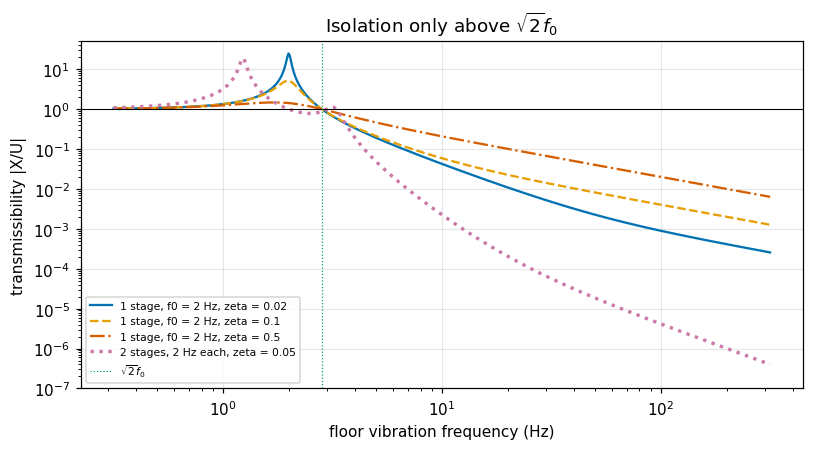

Figure 4. Transmissibility against frequency (log-log). One stage at f0 = 2 Hz with light (solid blue), medium (dashed orange) and heavy (dash-dot red) damping: all equal 1 at sqrt(2) f0 (dotted green line; Lean-proved for zero damping), amplify near resonance and isolate above it; heavy damping tames the peak but isolates less at high frequency. Two stages (dotted purple) fall twice as steeply (1/f^4).
Requirement: cut a 1 um floor motion at 10 Hz to 10 nm (lambda/100 at 1 um, i.e. T = 0.01): one undamped stage needs f0 <= 1.00 Hz; two equal lightly damped stages need f0 <= 2.87 Hz each. That is why optical tables float on ~1 Hz pneumatic legs, and sensitive AMO setups add a second stage.


In [8]:
d = b.two_stage_sym()
for e_ in d['equations']:
    display(Math(sp.latex(e_) + ' = 0'))
display(Math(r'\frac{X_2}{U}(s) = ' + sp.latex(d['H'])))
f = np.logspace(-0.5, 2.5, 500)
fig, ax = plt.subplots(figsize=(7.5, 4.2))
for z, c_, ls in [(0.02, OI['blue'], '-'), (0.1, OI['orange'], '--'), (0.5, OI['red'], '-.')]:
    ax.loglog(f, b.transmissibility(f/2.0, z), ls, color=c_, label=f'1 stage, f0 = 2 Hz, zeta = {z}')
ax.loglog(f, b.two_stage_transmissibility(f, 2.0, 2.0, 0.05, 0.05), ':', color=OI['purple'], lw=2.2, label='2 stages, 2 Hz each, zeta = 0.05')
ax.axhline(1, color=OI['black'], lw=0.7); ax.axvline(2*np.sqrt(2), color=OI['green'], lw=0.8, ls=':', label='$\\sqrt{2} f_0$')
ax.set(xlabel='floor vibration frequency (Hz)', ylabel='transmissibility |X/U|', ylim=(1e-7, 50), title='Isolation only above $\\sqrt{2}f_0$'); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()
f_need = b.required_f0_single(0.01, 10.0)
lo, hi_ = 0.1, 10.0
for _ in range(60):
    mid = 0.5*(lo + hi_)
    if b.two_stage_transmissibility(10.0, mid, mid, 0.05, 0.05) > 0.01: hi_ = mid
    else: lo = mid
print('Figure 4. Transmissibility against frequency (log-log). One stage at f0 = 2 Hz with light (solid blue), medium (dashed '
      'orange) and heavy (dash-dot red) damping: all equal 1 at sqrt(2) f0 (dotted green line; Lean-proved for zero damping), '
      'amplify near resonance and isolate above it; heavy damping tames the peak but isolates less at high frequency. Two '
      'stages (dotted purple) fall twice as steeply (1/f^4).')
print(f'Requirement: cut a 1 um floor motion at 10 Hz to 10 nm (lambda/100 at 1 um, i.e. T = 0.01): one undamped stage needs '
      f'f0 <= {f_need:.2f} Hz; two equal lightly damped stages need f0 <= {lo:.2f} Hz each. That is why optical tables '
      'float on ~1 Hz pneumatic legs, and sensitive AMO setups add a second stage.')

## Web

This notebook is exported as `notebooks/box_model_isolation.html` (`jupyter nbconvert --to html`), a single file that opens in any browser.

**References** (from memory; verify before citing)
[1] R. D. Knight, *Physics for Scientists and Engineers with Modern Physics*, 5th ed. Hoboken, NJ, USA: Pearson, ch. 40.
[2] K. P. Huber and G. Herzberg, *Molecular Spectra and Molecular Structure IV: Constants of Diatomic Molecules*. New York, NY, USA: Van Nostrand Reinhold, 1979.
[3] I. E. Gordon *et al.*, "The HITRAN2020 molecular spectroscopic database," *J. Quant. Spectrosc. Radiat. Transf.*, vol. 277, Art. no. 107949, 2022.
[4] A. M. Kaufman and K.-K. Ni, "Quantum science with optical tweezer arrays of ultracold atoms and molecules," *Nat. Phys.*, vol. 17, pp. 1324–1333, 2021.
[5] S. S. Rao, *Mechanical Vibrations*, 6th ed. Hoboken, NJ, USA: Pearson, 2017.
[6] The mathlib Community, "The Lean mathematical library," in *Proc. CPP*, 2020, pp. 367–381.

**Limitations.**
- The traps are 1D, and the box model has infinite walls.
- The CO constants are typed from memory and use only the two-term vibrational expansion, with no rotation.
- The isolation model is a lumped, 1D two-mass system with viscous damping. The "1 µm at 10 Hz" floor figure is an illustrative assumption, not a site measurement.